In [8]:
#component 3 start
# Import pandas library for data loading, cleaning, manipulation, and analysis.
import pandas as pd

In [9]:
# Load the raw traffic dataset into a pandas DataFrame.
# This dataset contains traffic information such as DateTime, Junction, Vehicles, and ID,weekend,holiday,event
traffic=pd.read_csv("Dataset_Uber Traffic (1).csv")


In [3]:
# Display the first five rows to understand the structure and contents of the traffic dataset.
traffic.head()

,DateTime,Junction,Vehicles,ID,Weekend,Holiday,Event
0,01-11-2015 00:00,1,15,20151101001,1,0,0
1,01-11-2015 01:00,1,13,20151101011,1,0,0
2,01-11-2015 02:00,1,10,20151101021,1,0,0
3,01-11-2015 03:00,1,7,20151101031,1,0,0
4,01-11-2015 04:00,1,9,20151101041,1,0,0


In [10]:
# Load the raw weather dataset into a pandas DataFrame.
# The weather data will later be integrated with the traffic data.
weather=pd.read_csv("open-meteo-17.40N78.46E515m.csv")

In [5]:
# Display the first five rows to understand the structure of the weather dataset.
weather.head()

,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),rain (mm)
0,2015-01-01T00:00,18.9,94,0.0,0.0
1,2015-01-01T01:00,18.8,95,0.0,0.0
2,2015-01-01T02:00,19.2,95,0.0,0.0
3,2015-01-01T03:00,20.9,86,0.0,0.0
4,2015-01-01T04:00,23.0,74,0.0,0.0


In [12]:
traffic.head()

,DateTime,Junction,Vehicles,ID,Weekend,Holiday,Event
0,01-11-2015 00:00,1,15,20151101001,1,0,0
1,01-11-2015 01:00,1,13,20151101011,1,0,0
2,01-11-2015 02:00,1,10,20151101021,1,0,0
3,01-11-2015 03:00,1,7,20151101031,1,0,0
4,01-11-2015 04:00,1,9,20151101041,1,0,0


In [13]:
# Convert traffic DateTime using the original day-month-year and hour-minute format.
# Convert the weather time column into datetime format for dataset integration.
traffic["DateTime"] = pd.to_datetime(
    traffic["DateTime"],
    format="%d-%m-%Y %H:%M"
)
weather["time"] = pd.to_datetime(weather["time"])

In [14]:
traffic.head()
weather.head()

,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),rain (mm)
0,2015-01-01 00:00:00,18.9,94,0.0,0.0
1,2015-01-01 01:00:00,18.8,95,0.0,0.0
2,2015-01-01 02:00:00,19.2,95,0.0,0.0
3,2015-01-01 03:00:00,20.9,86,0.0,0.0
4,2015-01-01 04:00:00,23.0,74,0.0,0.0


In [15]:
# Merge traffic and weather datasets using their matching DateTime values.
# A left join keeps all traffic records while adding the corresponding weather information.
integrated=pd.merge(traffic,weather,left_on="DateTime",right_on="time",how="left")

In [16]:
# Display the first few rows of the integrated dataset after merging traffic and weather data.
integrated.head()

,DateTime,Junction,Vehicles,ID,Weekend,Holiday,Event,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),rain (mm)
0,2015-11-01 00:00:00,1,15,20151101001,1,0,0,2015-11-01 00:00:00,20.8,83,0.0,0.0
1,2015-11-01 01:00:00,1,13,20151101011,1,0,0,2015-11-01 01:00:00,20.6,83,0.0,0.0
2,2015-11-01 02:00:00,1,10,20151101021,1,0,0,2015-11-01 02:00:00,22.1,76,0.0,0.0
3,2015-11-01 03:00:00,1,7,20151101031,1,0,0,2015-11-01 03:00:00,24.5,66,0.0,0.0
4,2015-11-01 04:00:00,1,9,20151101041,1,0,0,2015-11-01 04:00:00,26.8,57,0.0,0.0


In [17]:
# Check the number of rows and columns in the integrated dataset.
integrated.shape

(48120, 12)

In [18]:
# Check the number of missing values in each column after data integration.
# This helps verify whether the merge created any missing weather values.
integrated.isnull().sum()

DateTime                    0
Junction                    0
Vehicles                    0
ID                          0
Weekend                     0
Holiday                     0
Event                       0
time                        0
temperature_2m (°C)         0
relative_humidity_2m (%)    0
precipitation (mm)          0
rain (mm)                   0
dtype: int64

In [97]:
# Save the integrated traffic, weather, and event dataset as a CSV file.
# This file represents the merged dataset before feature engineering.
integrated.to_csv(
    "Integrated_Traffic_Weather_Event_Dataset.csv",
    index=False
)

In [21]:
# Recheck missing values after data integration and cleaning.
integrated.isnull().sum()

DateTime                    0
Junction                    0
Vehicles                    0
ID                          0
Weekend                     0
Holiday                     0
Event                       0
time                        0
temperature_2m (°C)         0
relative_humidity_2m (%)    0
precipitation (mm)          0
rain (mm)                   0
dtype: int64

In [22]:
# Check for duplicate records in the integrated dataset.
# Duplicate records can affect the accuracy of traffic analysis and model training.
integrated.duplicated().sum()

np.int64(0)

In [23]:
# Check the data type of each column to ensure the dataset is correctly formatted.
integrated.dtypes

DateTime                    datetime64[ns]
Junction                             int64
Vehicles                             int64
ID                                   int64
Weekend                              int64
Holiday                              int64
Event                                int64
time                        datetime64[ns]
temperature_2m (°C)                float64
relative_humidity_2m (%)             int64
precipitation (mm)                 float64
rain (mm)                          float64
dtype: object

In [24]:
# Check the time difference between consecutive traffic records.
# This helps verify whether the traffic data follows the expected hourly interval.
integrated['DateTime'].diff().value_counts().head()
integrated['DateTime'].diff().value_counts().head()

DateTime
0 days 01:00:00        48116
-608 days +01:00:00        2
-181 days +01:00:00        1
Name: count, dtype: int64

In [25]:
# Check the time difference between consecutive records separately for each junction.
# This helps confirm the hourly traffic observations for individual junctions.
integrated.groupby('Junction')['DateTime'].diff().value_counts().head()

DateTime
0 days 01:00:00    48116
Name: count, dtype: int64

In [26]:
# Display important traffic columns such as DateTime, Junction, and Vehicles.
# These columns are required for hourly traffic analysis.
integrated[['DateTime','Junction','Vehicles']].head()

,DateTime,Junction,Vehicles
0,2015-11-01 00:00:00,1,15
1,2015-11-01 01:00:00,1,13
2,2015-11-01 02:00:00,1,10
3,2015-11-01 03:00:00,1,7
4,2015-11-01 04:00:00,1,9


In [27]:
# Count the number of traffic observations available for each junction.
integrated.groupby('Junction')['Vehicles'].count()

Junction
1    14592
2    14592
3    14592
4     4344
Name: Vehicles, dtype: int64

In [28]:
# Calculate the total number of recorded vehicles for each junction.
integrated.groupby('Junction')['Vehicles'].sum()

Junction
1    657412
2    207983
3    199823
4     31501
Name: Vehicles, dtype: int64

In [29]:
# Standardize the selected weather features using StandardScaler.
# Standardization puts the variables on a comparable scale with mean approximately 0
# and standard deviation approximately 1.
from sklearn.preprocessing import StandardScaler
cols_to_scale=['temperature_2m (°C)',
    'relative_humidity_2m (%)',
    'precipitation (mm)',
    'rain (mm)']
scaler=StandardScaler()
integrated[cols_to_scale]=scaler.fit_transform(integrated[cols_to_scale])

In [30]:
# Display the standardized weather features to verify the transformation.
integrated[cols_to_scale].head()

,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),rain (mm)
0,-1.061944,1.190337,-0.199944,-0.199944
1,-1.099370,1.190337,-0.199944,-0.199944
2,-0.818677,0.884022,-0.199944,-0.199944
3,-0.369569,0.446428,-0.199944,-0.199944
4,0.060827,0.052594,-0.199944,-0.199944


In [31]:
# Generate descriptive statistics for the standardized weather features.
integrated[cols_to_scale].describe()

,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),rain (mm)
count,4.812000e+04,4.812000e+04,4.812000e+04,4.812000e+04
mean,6.567943e-16,-3.780111e-17,-1.417542e-17,-1.417542e-17
std,1.000010e+00,1.000010e+00,1.000010e+00,1.000010e+00
min,-2.633825e+00,-2.091614e+00,-1.999438e-01,-1.999438e-01
25%,-6.689743e-01,-8.663524e-01,-1.999438e-01,-1.999438e-01
50%,-7.016273e-02,8.834624e-03,-1.999438e-01,-1.999438e-01
75%,5.847874e-01,8.402623e-01,-1.999438e-01,-1.999438e-01
max,2.792905e+00,1.890487e+00,2.377678e+01,2.377678e+01


In [32]:
# Create time-based features from the DateTime column.
# Hour represents the hour of the day.
# DayOfWeek represents the day of the week.
# Month represents the month of the year.
integrated['Hour']=integrated['DateTime'].dt.hour
integrated['DayOfWeek']=integrated['DateTime'].dt.dayofweek
integrated['Month']=integrated['DateTime'].dt.month

In [33]:
# Display the newly created time-based features to verify the feature engineering.
integrated[['DateTime','Hour','DayOfWeek','Month']].head()

,DateTime,Hour,DayOfWeek,Month
0,2015-11-01 00:00:00,0,6,11
1,2015-11-01 01:00:00,1,6,11
2,2015-11-01 02:00:00,2,6,11
3,2015-11-01 03:00:00,3,6,11
4,2015-11-01 04:00:00,4,6,11


In [34]:
# Create a one-hour lag feature for each junction.
# Lag_1hour represents the vehicle count recorded in the previous hour.
# This helps the model capture temporal dependencies in traffic volume.
integrated['Lag_1hour']=integrated.groupby('Junction')['Vehicles'].shift(1)

In [35]:
# Display the current vehicle count and previous-hour vehicle count.
integrated[['Junction','Vehicles','Lag_1hour']].head()

,Junction,Vehicles,Lag_1hour
0,1,15,NaN
1,1,13,15.0
2,1,10,13.0
3,1,7,10.0
4,1,9,7.0


In [36]:
# Calculate correlations between numerical features and traffic volume.
# This helps identify features that may have a relationship with the target variable.
integrated.corr(numeric_only=True)['Vehicles'].sort_values(ascending=True)

Junction                   -0.613787
Weekend                    -0.150550
DayOfWeek                  -0.126027
temperature_2m (°C)        -0.061153
Month                      -0.022723
Event                      -0.012723
Holiday                    -0.008158
precipitation (mm)          0.022629
rain (mm)                   0.022629
relative_humidity_2m (%)    0.061088
Hour                        0.219938
ID                          0.227974
Lag_1hour                   0.970143
Vehicles                    1.000000
Name: Vehicles, dtype: float64

In [37]:
# Define the input features used for feature importance analysis.
# Remove rows with missing values created by the lag feature before model training.
from sklearn.ensemble import RandomForestRegressor
features=[ 'Junction',
    'Weekend',
    'Holiday',
    'Event',
    'Hour',
    'DayOfWeek',
    'Month',
    'Lag_1hour',
    'temperature_2m (°C)',
    'relative_humidity_2m (%)',
    'precipitation (mm)',
    'rain (mm)']
df_model=integrated[features+['Vehicles']].dropna()
x=df_model[features]
y=df_model['Vehicles']


In [38]:
# Train a Random Forest Regressor to evaluate the importance of each feature.
# Feature importance helps identify which variables contribute most to traffic prediction.
model=RandomForestRegressor(n_estimators=100,
                            random_state=42)
model.fit(x,y)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [39]:
integrated.columns

Index(['DateTime', 'Junction', 'Vehicles', 'ID', 'Weekend', 'Holiday', 'Event',
       'time', 'temperature_2m (°C)', 'relative_humidity_2m (%)',
       'precipitation (mm)', 'rain (mm)', 'Hour', 'DayOfWeek', 'Month',
       'Lag_1hour'],
      dtype='object')

In [40]:
# Calculate and sort feature importance scores from the Random Forest model.
# Higher importance indicates that the feature contributed more to the model's predictions.
importance=pd.Series(
    model.feature_importances_,
                     index=features
                    ).sort_values(ascending=False)
importance

Lag_1hour                   0.944791
Hour                        0.020085
temperature_2m (°C)         0.010564
relative_humidity_2m (%)    0.008017
Junction                    0.004946
Month                       0.004492
DayOfWeek                   0.004249
Weekend                     0.000920
rain (mm)                   0.000674
precipitation (mm)          0.000649
Holiday                     0.000330
Event                       0.000283
dtype: float64

In [41]:
# Select the most influential features identified during feature importance analysis.
# These features can be used for efficient model training.
selected_features = [
    'Lag_1hour',
    'Hour',
    'temperature_2m (°C)',
    'relative_humidity_2m (%)',
    'Junction',
    'Month',
    'DayOfWeek'
]
X = integrated[selected_features]
y = integrated['Vehicles']

In [43]:
# Display the first five rows of the input features used for model training.
# This helps verify that the selected features are prepared correctly.
x.head()

,Junction,Weekend,Holiday,Event,Hour,DayOfWeek,Month,Lag_1hour,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),rain (mm)
1,1,1,0,0,1,6,11,15.0,-1.099370,1.190337,-0.199944,-0.199944
2,1,1,0,0,2,6,11,13.0,-0.818677,0.884022,-0.199944,-0.199944
3,1,1,0,0,3,6,11,10.0,-0.369569,0.446428,-0.199944,-0.199944
4,1,1,0,0,4,6,11,7.0,0.060827,0.052594,-0.199944,-0.199944
5,1,1,0,0,5,6,11,9.0,0.397659,-0.297481,-0.199944,-0.199944


In [44]:
# Display the first five values of the target variable, Vehicles.
# This helps verify the traffic volume values used as the prediction target.
y.head()

0    15
1    13
2    10
3     7
4     9
Name: Vehicles, dtype: int64

In [45]:
# Calculate the average number of vehicles for each hour at each junction.
# This helps identify the hourly traffic pattern and peak traffic periods
# for individual junctions.
hourly_congestion=(integrated.groupby(['Junction','Hour'])['Vehicles']
                   .mean()
                   .reset_index()
                  )
                                    

In [46]:
# Display the calculated average hourly traffic volume for each junction.
# This helps verify the hourly congestion values.
hourly_congestion.head()

,Junction,Hour,Vehicles
0,1,0,45.738487
1,1,1,39.156250
2,1,2,33.907895
3,1,3,29.430921
4,1,4,25.654605


In [47]:
# Extract the ISO week number from the DateTime column.
# This helps analyse traffic patterns across different weeks of the year.
integrated['Week']=integrated['DateTime'].dt.isocalendar().week

In [48]:
# Display the DateTime and Week columns to verify the calculated week numbers.
# This helps confirm that the week number has been correctly extracted from DateTime.
integrated[['DateTime','Week']].head()

,DateTime,Week
0,2015-11-01 00:00:00,44
1,2015-11-01 01:00:00,44
2,2015-11-01 02:00:00,44
3,2015-11-01 03:00:00,44
4,2015-11-01 04:00:00,44


In [49]:
 #Sort the hourly congestion data by vehicle count in descending order.
# This helps identify the top 10 hours with the highest average traffic volume.
hourly_congestion.sort_values('Vehicles',ascending=False).head(10)

,Junction,Hour,Vehicles
19,1,19,58.804276
20,1,20,57.401316
12,1,12,57.254934
11,1,11,56.187500
18,1,18,55.411184
14,1,14,54.733553
21,1,21,54.537829
15,1,15,54.218750
22,1,22,52.963816
16,1,16,51.911184


In [51]:
# Calculate the 3-hour moving average of traffic volume.
# This helps smooth short-term fluctuations and identify the overall traffic trend.
hourly_congestion['Moving_Average']=(hourly_congestion['Vehicles'].rolling(3).mean()
                                    )

In [52]:
# Display the first 10 rows of the hourly congestion data.
# This helps verify the calculated moving average values.
hourly_congestion.head(10)

,Junction,Hour,Vehicles,Moving_Average
0,1,0,45.738487,NaN
1,1,1,39.156250,NaN
2,1,2,33.907895,39.600877
3,1,3,29.430921,34.165022
4,1,4,25.654605,29.664474
5,1,5,24.067434,26.384320
6,1,6,26.080592,25.267544
7,1,7,29.526316,26.558114
8,1,8,32.735197,29.447368
9,1,9,39.003289,33.754934


In [53]:

integrated.head(10)

,DateTime,Junction,Vehicles,ID,Weekend,Holiday,Event,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),rain (mm),Hour,DayOfWeek,Month,Lag_1hour,Week
0,2015-11-01 00:00:00,1,15,20151101001,1,0,0,2015-11-01 00:00:00,-1.061944,1.190337,-0.199944,-0.199944,0,6,11,NaN,44
1,2015-11-01 01:00:00,1,13,20151101011,1,0,0,2015-11-01 01:00:00,-1.099370,1.190337,-0.199944,-0.199944,1,6,11,15.0,44
2,2015-11-01 02:00:00,1,10,20151101021,1,0,0,2015-11-01 02:00:00,-0.818677,0.884022,-0.199944,-0.199944,2,6,11,13.0,44
3,2015-11-01 03:00:00,1,7,20151101031,1,0,0,2015-11-01 03:00:00,-0.369569,0.446428,-0.199944,-0.199944,3,6,11,10.0,44
4,2015-11-01 04:00:00,1,9,20151101041,1,0,0,2015-11-01 04:00:00,0.060827,0.052594,-0.199944,-0.199944,4,6,11,7.0,44
5,2015-11-01 05:00:00,1,6,20151101051,1,0,0,2015-11-01 05:00:00,0.397659,-0.297481,-0.199944,-0.199944,5,6,11,9.0,44
6,2015-11-01 06:00:00,1,9,20151101061,1,0,0,2015-11-01 06:00:00,0.659639,-0.560037,-0.199944,-0.199944,6,6,11,6.0,44
7,2015-11-01 07:00:00,1,8,20151101071,1,0,0,2015-11-01 07:00:00,0.809342,-0.691315,-0.199944,-0.199944,7,6,11,9.0,44
8,2015-11-01 08:00:00,1,11,20151101081,1,0,0,2015-11-01 08:00:00,0.884193,-0.822593,-0.199944,-0.199944,8,6,11,8.0,44
9,2015-11-01 09:00:00,1,12,20151101091,1,0,0,2015-11-01 09:00:00,0.940332,-0.910112,-0.199944,-0.199944,9,6,11,11.0,44


In [54]:
# Calculate the standard deviation of vehicle counts for each hour.
# This helps identify the variation in traffic volume across different hours.
hourly_congestion.groupby('Hour')['Vehicles'].std()

Hour
0     17.173051
1     15.038724
2     13.076294
3     11.348845
4      9.856448
5      9.158948
6      9.997981
7     11.303731
8     12.414071
9     14.827245
10    19.021177
11    21.564690
12    21.591554
13    19.226406
14    20.517909
15    20.179188
16    19.239556
17    19.199584
18    20.933058
19    22.234979
20    21.371855
21    20.384546
22    19.717001
23    18.684860
Name: Vehicles, dtype: float64

In [55]:
# Calculate the average traffic volume for each hour separately for weekdays and weekends.
# This helps identify differences in traffic patterns between weekdays and weekends.
weekday_weekend_pattern=(integrated.groupby(['Weekend','Hour'])['Vehicles']
                         .mean()
                         .reset_index())
weekday_weekend_pattern

,Weekend,Hour,Vehicles
0,0,0,24.399303
1,0,1,20.495470
2,0,2,17.912195
3,0,3,15.585366
4,0,4,13.597909
5,0,5,12.887108
6,0,6,13.913589
7,0,7,15.926829
8,0,8,17.655749
9,0,9,20.914286


In [56]:
# Calculate the average traffic volume for each hour of every month.
# This helps identify monthly and seasonal variations in traffic volume.
monthly_pattern=(integrated.groupby(['Month','Hour'])['Vehicles']
                 .mean()
                 .reset_index())
monthly_pattern.head(20)

,Month,Hour,Vehicles
0,1,0,20.179724
1,1,1,16.907834
2,1,2,14.824885
3,1,3,13.622120
4,1,4,11.843318
5,1,5,10.958525
6,1,6,11.322581
7,1,7,12.603687
8,1,8,13.976959
9,1,9,16.875576


In [57]:
# Define a function to classify each month into a season.
# This helps analyse traffic patterns across different seasons.
def get_season(month):
    if month in [12,1,2]:
        return 'Winter'
    elif month in [3,4,5]:
        return 'Summer'
    elif month in [6,7,8,9]:
        return 'Monsoon'
    else:
        return 'Post_monsoon'
integrated['Season']=integrated['Month'].apply(get_season)
integrated[['Month','Season']]

,Month,Season
0,11,Post_monsoon
1,11,Post_monsoon
2,11,Post_monsoon
3,11,Post_monsoon
4,11,Post_monsoon
...,...,...
48115,6,Monsoon
48116,6,Monsoon
48117,6,Monsoon
48118,6,Monsoon


In [58]:
# Select traffic, weather, holiday, and event variables for correlation analysis.
# This helps identify how these factors are related to traffic volume.
factors=[ 'Vehicles',
    'temperature_2m (°C)',
    'relative_humidity_2m (%)',
    'precipitation (mm)',
    'rain (mm)',
    'Holiday',
    'Event']
integrated[factors].corr()['Vehicles'].sort_values(ascending=False)

Vehicles                    1.000000
relative_humidity_2m (%)    0.061088
precipitation (mm)          0.022629
rain (mm)                   0.022629
Holiday                    -0.008158
Event                      -0.012723
temperature_2m (°C)        -0.061153
Name: Vehicles, dtype: float64

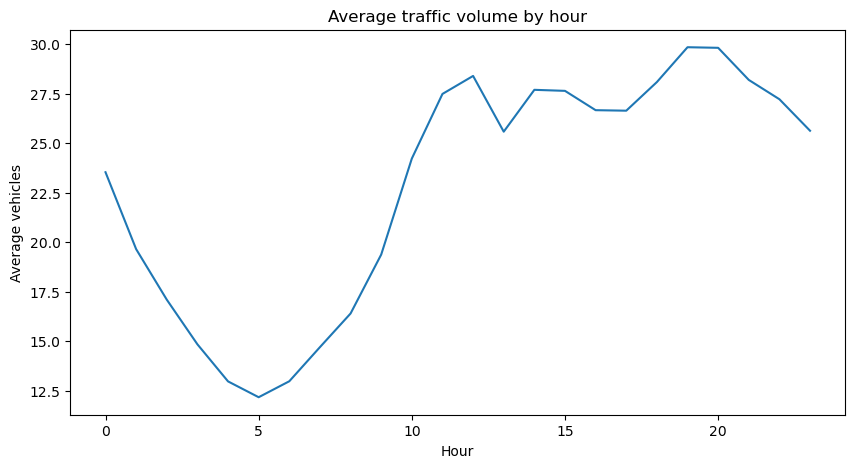

In [59]:
# Calculate and plot the average traffic volume for each hour.
import matplotlib.pyplot as plt
peak_hour=(integrated.groupby('Hour')['Vehicles']
           .mean())
peak_hour.plot(kind='line',
               figsize=(10,5)
              )
plt.title('Average traffic volume by hour')
plt.xlabel('Hour')
plt.ylabel('Average vehicles')
plt.show()

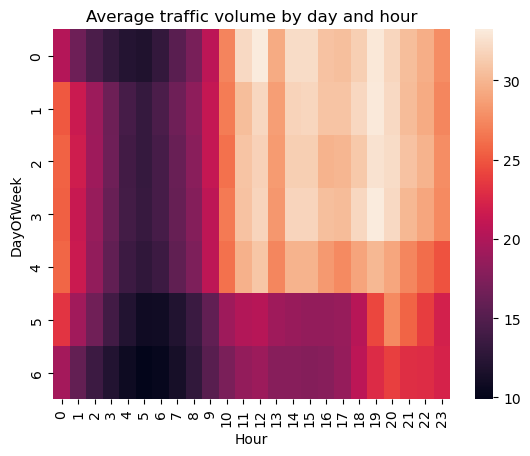

In [60]:
# Create a heatmap to visualize average traffic volume by day and hour.
import seaborn as sns
import matplotlib.pyplot as plt
day_hour=integrated.pivot_table(
    values='Vehicles',
    index='DayOfWeek',
    columns='Hour',
    aggfunc='mean')
sns.heatmap(day_hour)
plt.title('Average traffic volume by day and hour')
plt.xlabel('Hour')
plt.ylabel('DayOfWeek')
plt.show()


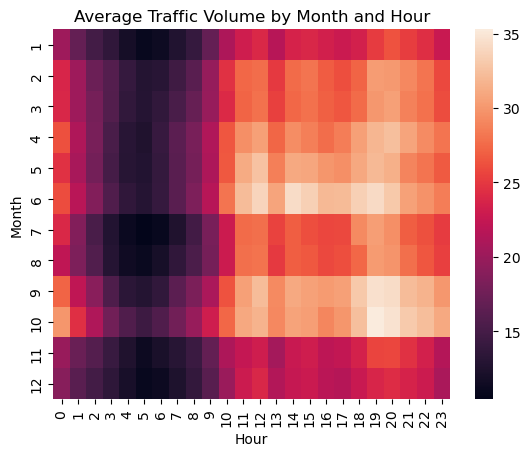

In [61]:
# Create a heatmap to visualize average traffic volume by month and hour.
month_hour=integrated.pivot_table(
    values='Vehicles',
    index='Month',
    columns='Hour',
    aggfunc='mean')
sns.heatmap(month_hour)
plt.title('Average Traffic Volume by Month and Hour')
plt.xlabel('Hour')
plt.ylabel('Month')
plt.show()

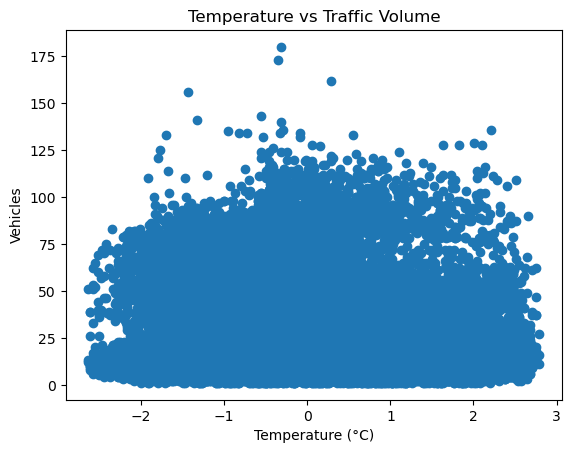

In [62]:
# Create a scatter plot to visualize the relationship between temperature and traffic volume.
plt.scatter(integrated['temperature_2m (°C)'],
    integrated['Vehicles']
)

plt.title('Temperature vs Traffic Volume')
plt.xlabel('Temperature (°C)')
plt.ylabel('Vehicles')
plt.show()

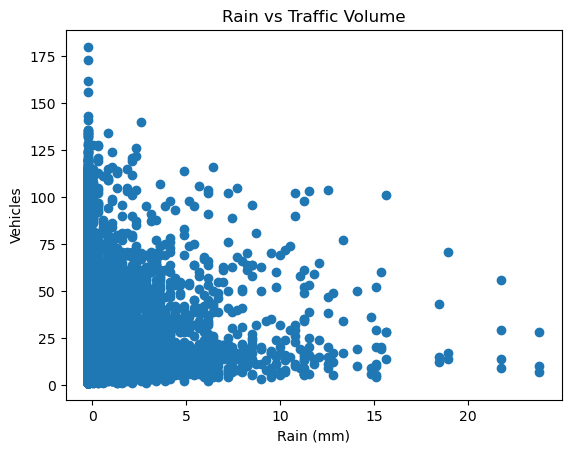

In [63]:
# Create a scatter plot to visualize the relationship between rain and traffic volume.
plt.scatter(
    integrated['rain (mm)'],
    integrated['Vehicles'])
plt.title('Rain vs Traffic Volume')
plt.xlabel('Rain (mm)')
plt.ylabel('Vehicles')
plt.show()

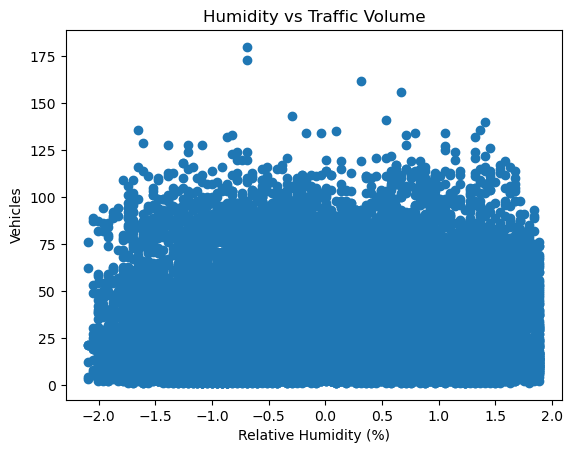

In [64]:
# Create a scatter plot to visualize the relationship between humidity and traffic volume.
plt.scatter(
    integrated['relative_humidity_2m (%)'],
    integrated['Vehicles'])
plt.title('Humidity vs Traffic Volume')
plt.xlabel('Relative Humidity (%)')
plt.ylabel('Vehicles')
plt.show()

In [65]:
# Calculate the average traffic volume for each hour at each junction.
junction_peak=(integrated.groupby(['Junction','Hour'])['Vehicles']
               .mean()
               .reset_index())
pd.set_option('display.max_rows', None)
junction_peak

,Junction,Hour,Vehicles
0,1,0,45.738487
1,1,1,39.156250
2,1,2,33.907895
3,1,3,29.430921
4,1,4,25.654605
5,1,5,24.067434
6,1,6,26.080592
7,1,7,29.526316
8,1,8,32.735197
9,1,9,39.003289


In [66]:
# Sort the junction-wise traffic data to identify the highest traffic hours.
junction_peak = (
    integrated.groupby(['Junction', 'Hour'])['Vehicles']
    .mean()
    .reset_index()
    .sort_values(['Junction', 'Vehicles'], ascending=[True, False]))

junction_peak

,Junction,Hour,Vehicles
19,1,19,58.804276
20,1,20,57.401316
12,1,12,57.254934
11,1,11,56.187500
18,1,18,55.411184
14,1,14,54.733553
21,1,21,54.537829
15,1,15,54.218750
22,1,22,52.963816
16,1,16,51.911184


In [67]:
# Calculate average traffic volume for weekdays and weekends for each junction.
junction_weekend=(integrated.groupby(['Junction','Weekend'])['Vehicles']
                  .mean()
                  .reset_index())
junction_weekend

,Junction,Weekend,Vehicles
0,1,0,49.766858
1,1,1,33.199904
2,2,0,15.834291
3,2,1,10.277697
4,3,0,13.793199
5,3,1,13.444605
6,4,0,7.648397
7,4,1,6.240196


In [68]:
# Calculate the average traffic volume for each month at each junction.
junction_month = (
    integrated.groupby(['Junction', 'Month'])['Vehicles']
    .mean()
    .reset_index())

junction_month

,Junction,Month,Vehicles
0,1,1,41.249328
1,1,2,46.000731
2,1,3,46.590054
3,1,4,46.865278
4,1,5,51.899866
5,1,6,55.079167
6,1,7,39.127688
7,1,8,41.915323
8,1,9,47.741667
9,1,10,50.032258


In [69]:
# Calculate the average traffic volume for each season at each junction.
junction_season = (
    integrated.groupby(['Junction', 'Season'])['Vehicles']
    .mean()
    .reset_index())

junction_season

,Junction,Season,Vehicles
0,1,Monsoon,47.692982
1,1,Post_monsoon,41.292125
2,1,Summer,48.468976
3,1,Winter,41.253913
4,2,Monsoon,14.514254
5,2,Post_monsoon,12.293498
6,2,Summer,17.097826
7,2,Winter,12.127532
8,3,Monsoon,14.054276
9,3,Post_monsoon,12.188187


In [70]:
#component 3 end
# Calculate the correlation of traffic volume with weather, holiday, and event factors for each junction.
junction_factors = (
    integrated.groupby('Junction')[
        ['Vehicles',
         'temperature_2m (°C)',
         'relative_humidity_2m (%)',
         'rain (mm)',
         'Holiday',
         'Event']
    ].corr()['Vehicles'])

junction_factors

Junction                          
1         Vehicles                    1.000000
          temperature_2m (°C)        -0.101317
          relative_humidity_2m (%)    0.084544
          rain (mm)                   0.040020
          Holiday                    -0.014016
          Event                      -0.020090
2         Vehicles                    1.000000
          temperature_2m (°C)        -0.012090
          relative_humidity_2m (%)    0.029942
          rain (mm)                   0.010040
          Holiday                    -0.010481
          Event                      -0.054734
3         Vehicles                    1.000000
          temperature_2m (°C)        -0.063082
          relative_humidity_2m (%)    0.026215
          rain (mm)                   0.012189
          Holiday                    -0.022009
          Event                       0.017480
4         Vehicles                    1.000000
          temperature_2m (°C)        -0.217987
          relative_humidi

In [71]:
# Train and evaluate an ARIMA time-series model for Junction 1 traffic prediction.
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

junction_1 = integrated[integrated['Junction'] == 1].copy()
junction_1 = junction_1.sort_values('DateTime')
traffic_series = junction_1['Vehicles'].reset_index(drop=True)

train_size = int(len(traffic_series) * 0.80)

train = traffic_series.iloc[:train_size]
test = traffic_series.iloc[train_size:]

print("Train:", len(train))
print("Test:", len(test))

arima_model = ARIMA(train, order=(1, 1, 1))
arima_fit = arima_model.fit()

arima_pred = arima_fit.forecast(steps=len(test))

mae = mean_absolute_error(test, arima_pred)
rmse = np.sqrt(mean_squared_error(test, arima_pred))
r2 = r2_score(test, arima_pred)

print("ARIMA MAE:", mae)
print("ARIMA RMSE:", rmse)
print("ARIMA R²:", r2)

Train: 11673
Test: 2919
ARIMA MAE: 21.683420685289423
ARIMA RMSE: 27.55512058800431
ARIMA R²: -0.361463884308479


In [72]:
# Import Gradient Boosting Regressor and evaluation tools for model training.
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
junction_1 = integrated[integrated['Junction'] == 1].copy()

junction_1 = junction_1.sort_values('DateTime')

features = [
    'Junction',
    'Hour',
    'DayOfWeek',
    'Month',
    'Weekend',
    'Holiday',
    'Event',
    'Lag_1hour',
    'temperature_2m (°C)',
    'relative_humidity_2m (%)',
    'precipitation (mm)',
    'rain (mm)'
]

df_model = junction_1[features + ['Vehicles']].dropna()

X = df_model[features]
y = df_model['Vehicles']

train_size = int(len(df_model) * 0.80)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)


gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

mae = mean_absolute_error(y_test, gb_pred)
rmse = np.sqrt(mean_squared_error(y_test, gb_pred))
r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting MAE:", mae)
print("Gradient Boosting RMSE:", rmse)
print("Gradient Boosting R²:", r2)

Gradient Boosting MAE: 5.137004950609776
Gradient Boosting RMSE: 7.371392137341807
Gradient Boosting R²: 0.9025682454290983


In [79]:
# Build and evaluate an LSTM model for Junction 1 traffic prediction.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
junction_1 = integrated[integrated['Junction'] == 1].copy()
junction_1 = junction_1.sort_values('DateTime')
traffic = junction_1['Vehicles'].values.reshape(-1, 1)

scaler = MinMaxScaler()
traffic_scaled = scaler.fit_transform(traffic)

look_back = 24

X = []
y = []

for i in range(look_back, len(traffic_scaled)):
    X.append(traffic_scaled[i-look_back:i, 0])
    y.append(traffic_scaled[i, 0])

X = np.array(X)
y = np.array(y)
X = X.reshape(X.shape[0], X.shape[1], 1)

train_size = int(len(X) * 0.80)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

lstm_model = Sequential([
    LSTM(50, input_shape=(look_back, 1)),
    Dense(1)
])

lstm_model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)


lstm_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    verbose=1
)


lstm_pred_scaled = lstm_model.predict(X_test)

lstm_pred = scaler.inverse_transform(lstm_pred_scaled)
y_test_original = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

mae = mean_absolute_error(y_test_original, lstm_pred)
rmse = np.sqrt(mean_squared_error(y_test_original, lstm_pred))
r2 = r2_score(y_test_original, lstm_pred)

print("LSTM MAE:", mae)
print("LSTM RMSE:", rmse)
print("LSTM R²:", r2)

Epoch 1/10


C:\Users\thanusha paidipati\AppData\Local\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


365/365 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.0065
Epoch 2/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0018
Epoch 3/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.0014
Epoch 4/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0012
Epoch 5/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0012
Epoch 6/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0012
Epoch 7/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0011
Epoch 8/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0011
Epoch 9/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0011
Epoch 10/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.0011
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
LSTM MAE: 4.593627557250516
LSTM RMSE: 6.249926456199969
LSTM R²: 0.9300407952137861


In [80]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [81]:
# Create a DataFrame to compare the performance of different forecasting models.
results = pd.DataFrame({
    'Model': ['ARIMA', 'Gradient Boosting'],
    'MAE': [21.6834, 5.1370],
    'RMSE': [27.5551, 7.3714],
    'R2': [-0.3615, 0.9026]
})

results

,Model,MAE,RMSE,R2
0,ARIMA,21.6834,27.5551,-0.3615
1,Gradient Boosting,5.1370,7.3714,0.9026


In [78]:
# Split Junction 1 traffic data into 80% training and 20% validation data.
integrated = integrated.sort_values('DateTime')
junction_1 = integrated[integrated['Junction'] == 1].copy()

junction_1 = junction_1.reset_index(drop=True)

train_size = int(len(junction_1) * 0.80)

train_data = junction_1.iloc[:train_size]
validation_data = junction_1.iloc[train_size:]

print("Total rows:", len(junction_1))
print("Training rows:", len(train_data))
print("Validation rows:", len(validation_data))

print("\nTraining period:")
print(train_data['DateTime'].min(), "to", train_data['DateTime'].max())

print("\nValidation period:")
print(validation_data['DateTime'].min(), "to", validation_data['DateTime'].max())

Total rows: 14592
Training rows: 11673
Validation rows: 2919

Training period:
2015-11-01 00:00:00 to 2017-03-01 08:00:00

Validation period:
2017-03-01 09:00:00 to 2017-06-30 23:00:00


In [82]:
# Prepare the training and validation data for the Gradient Boosting model.
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

# Prepare Gradient Boosting training data separately
gb_train = train_data[features + ['Vehicles']].dropna()
gb_validation = validation_data[features + ['Vehicles']].dropna()

X_gb_train = gb_train[features]
y_gb_train = gb_train['Vehicles']

X_gb_validation = gb_validation[features]
y_gb_validation = gb_validation['Vehicles']

print("Training shape:", X_gb_train.shape)
print("Validation shape:", X_gb_validation.shape)

Training shape: (11672, 12)
Validation shape: (2919, 12)


In [101]:
# Tune the Gradient Boosting model to find the best parameters.
gb = GradientBoostingRegressor(random_state=42)

param_grid = {
    'n_estimators': [50, 100, 150, 200],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': [2, 5, 10]
}

random_search = RandomizedSearchCV(
    estimator=gb,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_gb_train, y_gb_train)

print("Best Parameters:")
print(random_search.best_params_)
gb = GradientBoostingRegressor(random_state=42)

param_grid = {
    'n_estimators': [50, 100, 150, 200],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': [2, 5, 10]
}

random_search = RandomizedSearchCV(
    estimator=gb,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_gb_train, y_gb_train)

print("Best Parameters:")
print(random_search.best_params_)

Best Parameters:
{'n_estimators': 50, 'min_samples_split': 5, 'max_depth': 5, 'learning_rate': 0.1}
Best Parameters:
{'n_estimators': 50, 'min_samples_split': 5, 'max_depth': 5, 'learning_rate': 0.1}


In [84]:
# Evaluate the best Gradient Boosting model using MAE, RMSE, and R².
best_gb = random_search.best_estimator_

gb_pred = best_gb.predict(X_gb_validation)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_gb_validation, gb_pred)
rmse = np.sqrt(mean_squared_error(y_gb_validation, gb_pred))
r2 = r2_score(y_gb_validation, gb_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 5.740706864787583
RMSE: 8.20123431763626
R²: 0.8793964937628362


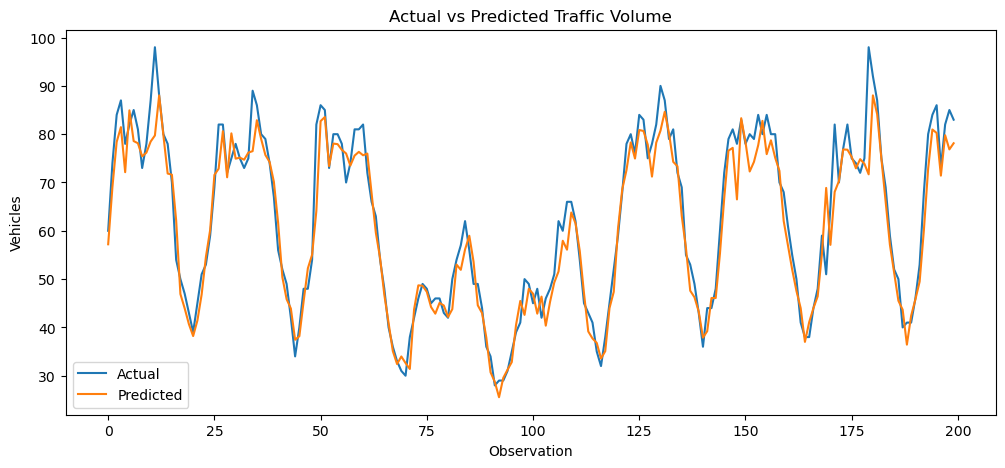

In [85]:
# Plot actual and predicted traffic volume for comparison.
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_gb_validation.values[:200],
    label='Actual'
)

plt.plot(
    gb_pred[:200],
    label='Predicted'
)

plt.title('Actual vs Predicted Traffic Volume')
plt.xlabel('Observation')
plt.ylabel('Vehicles')
plt.legend()
plt.show()

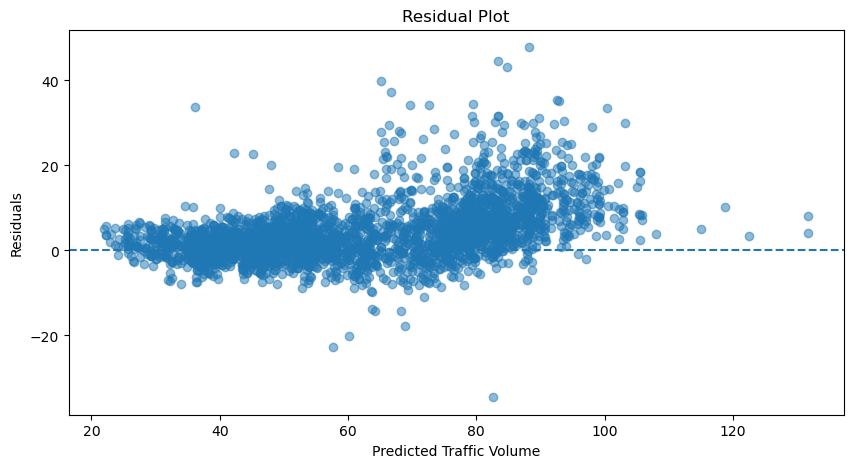

In [86]:
# Plot the residuals to check the prediction errors of the model.
residuals = y_gb_validation.values - gb_pred

plt.figure(figsize=(10, 5))

plt.scatter(
    gb_pred,
    residuals,
    alpha=0.5
)

plt.axhline(y=0, linestyle='--')

plt.title('Residual Plot')
plt.xlabel('Predicted Traffic Volume')
plt.ylabel('Residuals')

plt.show()

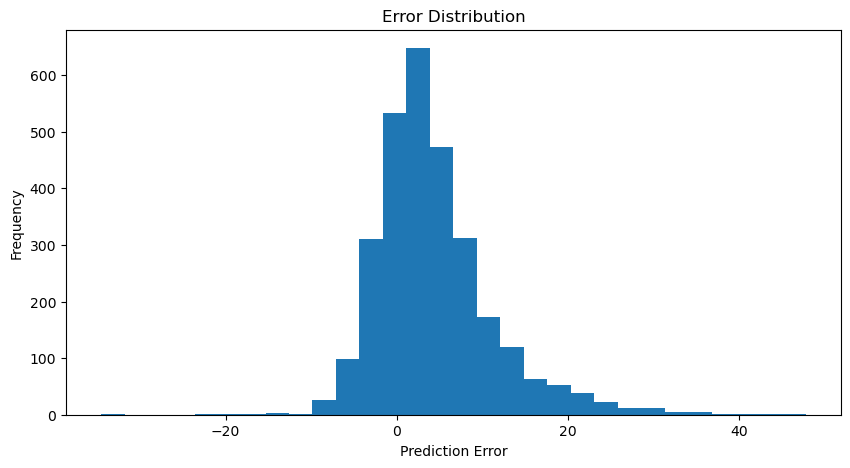

In [87]:
# Plot the distribution of prediction errors.
plt.figure(figsize=(10, 5))

plt.hist(
    residuals,
    bins=30
)

plt.title('Error Distribution')
plt.xlabel('Prediction Error')
plt.ylabel('Frequency')

plt.show()

In [88]:
# Use time-series cross-validation to evaluate the Gradient Boosting model.
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor
import numpy as np

tscv = TimeSeriesSplit(n_splits=5)

gb_cv = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

cv_scores = cross_val_score(
    gb_cv,
    X_gb_train,
    y_gb_train,
    cv=tscv,
    scoring='neg_root_mean_squared_error'
)

rmse_scores = -cv_scores

print("RMSE for each fold:")
print(rmse_scores)

print("\nAverage RMSE:", np.mean(rmse_scores))
print("RMSE Standard Deviation:", np.std(rmse_scores))

RMSE for each fold:
[4.32835218 4.26292842 6.70393655 9.02031441 8.24568683]

Average RMSE: 6.5122436765859275
RMSE Standard Deviation: 1.9575899115260205


In [89]:
# Store and display the RMSE results from each cross-validation fold.
import pandas as pd
import numpy as np

cv_results = pd.DataFrame({
    'Fold': range(1, len(rmse_scores) + 1),
    'RMSE': rmse_scores
})

print("Cross-Validation Results")
print(cv_results)

print("\nAverage RMSE:", np.mean(rmse_scores))
print("RMSE Standard Deviation:", np.std(rmse_scores))

Cross-Validation Results
   Fold      RMSE
0     1  4.328352
1     2  4.262928
2     3  6.703937
3     4  9.020314
4     5  8.245687

Average RMSE: 6.5122436765859275
RMSE Standard Deviation: 1.9575899115260205


In [90]:
# Create an error analysis table to compare actual and predicted traffic values.
import pandas as pd
import numpy as np

residuals = y_gb_validation.values - gb_pred

error_analysis = pd.DataFrame({
    'Actual': y_gb_validation.values,
    'Predicted': gb_pred,
    'Error': residuals,
    'Absolute_Error': np.abs(residuals)
})

print(error_analysis.head(10))

   Actual  Predicted     Error  Absolute_Error
0      60  57.207606  2.792394        2.792394
1      74  69.055407  4.944593        4.944593
2      84  78.401581  5.598419        5.598419
3      87  81.462225  5.537775        5.537775
4      78  72.131267  5.868733        5.868733
5      82  84.932111 -2.932111        2.932111
6      85  78.572554  6.427446        6.427446
7      81  78.120728  2.879272        2.879272
8      73  75.405077 -2.405077        2.405077
9      78  76.184301  1.815699        1.815699


In [91]:
# Calculate summary statistics for the prediction errors.
print("Mean Error:", np.mean(residuals))
print("Mean Absolute Error:", np.mean(np.abs(residuals)))
print("Error Standard Deviation:", np.std(residuals))

Mean Error: 4.386540615929966
Mean Absolute Error: 5.740706864787583
Error Standard Deviation: 6.929538639590041


In [92]:
# Identify the observations with the largest prediction errors.
largest_errors = error_analysis.sort_values(
    'Absolute_Error',
    ascending=False
).head(10)

print(largest_errors)

      Actual  Predicted      Error  Absolute_Error
1970     136  88.167779  47.832221       47.832221
2834     128  83.431766  44.568234       44.568234
2042     128  84.819870  43.180130       43.180130
1657     105  65.223801  39.776199       39.776199
2881     104  66.669431  37.330569       37.330569
2139     128  92.597692  35.402308       35.402308
2138     128  92.903270  35.096730       35.096730
962      114  79.425675  34.574325       34.574325
2173      48  82.544978 -34.544978       34.544978
2713     107  72.708296  34.291704       34.291704


In [93]:
# Calculate the average prediction error for each hour.
error_analysis['Hour'] = validation_data.loc[
    gb_validation.index, 'Hour'
].values

hourly_error = (
    error_analysis.groupby('Hour')['Absolute_Error']
    .mean()
)

print(hourly_error)

Hour
0      3.429909
1      3.165590
2      3.046669
3      2.732974
4      2.473266
5      2.557119
6      2.975064
7      3.103519
8      3.302158
9      3.665373
10    10.321748
11    12.094274
12    10.526722
13     8.050483
14     7.877824
15     7.250622
16     5.983450
17     6.990448
18     8.004336
19     7.457030
20     6.653598
21     4.897406
22     5.262399
23     5.751049
Name: Absolute_Error, dtype: float64


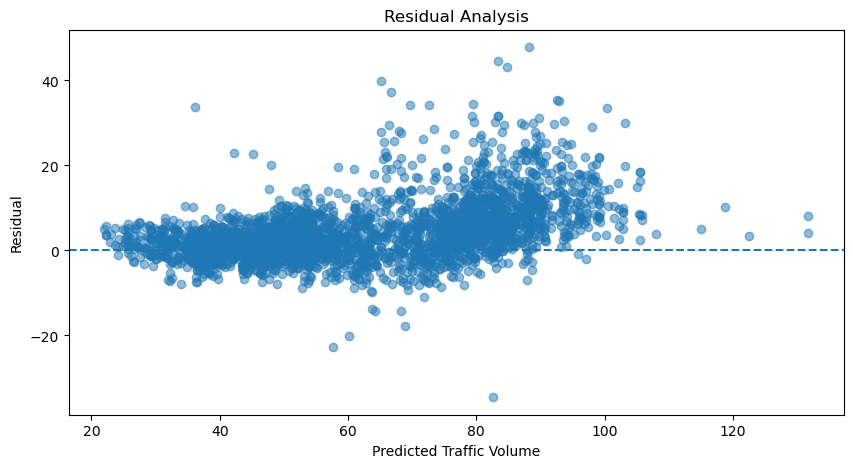

In [94]:
# Plot residuals against predicted traffic volume for residual analysis.
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.scatter(gb_pred, residuals, alpha=0.5)
plt.axhline(y=0, linestyle='--')

plt.title('Residual Analysis')
plt.xlabel('Predicted Traffic Volume')
plt.ylabel('Residual')
plt.show()

In [95]:
# Add a 24-hour lag feature and define the improved feature set.
integrated['Lag_24hour'] = (
    integrated.groupby('Junction')['Vehicles'].shift(24)
)

features_improved = [
    'Junction',
    'Hour',
    'DayOfWeek',
    'Month',
    'Weekend',
    'Holiday',
    'Event',
    'Lag_1hour',
    'Lag_24hour',
    'temperature_2m (°C)',
    'relative_humidity_2m (%)',
    'precipitation (mm)'
]

print("Improved Features:")
print(features_improved)
integrated['Lag_24hour'] = (
    integrated.groupby('Junction')['Vehicles'].shift(24)
)

features_improved = [
    'Junction',
    'Hour',
    'DayOfWeek',
    'Month',
    'Weekend',
    'Holiday',
    'Event',
    'Lag_1hour',
    'Lag_24hour',
    'temperature_2m (°C)',
    'relative_humidity_2m (%)',
    'precipitation (mm)'
]

print("Improved Features:")
print(features_improved)

Improved Features:
['Junction', 'Hour', 'DayOfWeek', 'Month', 'Weekend', 'Holiday', 'Event', 'Lag_1hour', 'Lag_24hour', 'temperature_2m (°C)', 'relative_humidity_2m (%)', 'precipitation (mm)']


In [96]:
# Train and evaluate a Random Forest model using the improved features.
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
model_data = integrated[
    features_improved + ['Vehicles']
].dropna()

train_size = int(len(model_data) * 0.80)

train_data_improved = model_data.iloc[:train_size]
validation_data_improved = model_data.iloc[train_size:]

X_train_improved = train_data_improved[features_improved]
y_train_improved = train_data_improved['Vehicles']

X_validation_improved = validation_data_improved[features_improved]
y_validation_improved = validation_data_improved['Vehicles']

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_improved, y_train_improved)

rf_pred = rf_model.predict(X_validation_improved)

print("Random Forest MAE:",
      mean_absolute_error(y_validation_improved, rf_pred))

print("Random Forest RMSE:",
      np.sqrt(mean_squared_error(y_validation_improved, rf_pred)))

print("Random Forest R²:",
      r2_score(y_validation_improved, rf_pred))

Random Forest MAE: 3.1827143336702166
Random Forest RMSE: 5.155238986088817
Random Forest R²: 0.9640885038994568


In [99]:
integrated.head(20)

,DateTime,Junction,Vehicles,ID,Weekend,Holiday,Event,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),rain (mm),Hour,DayOfWeek,Month,Lag_1hour,Week,Season,Lag_24hour
0,2015-11-01 00:00:00,1,15,20151101001,1,0,0,2015-11-01 00:00:00,-1.061944,1.190337,-0.199944,-0.199944,0,6,11,NaN,44,Post_monsoon,NaN
14592,2015-11-01 00:00:00,2,6,20151101002,1,0,0,2015-11-01 00:00:00,-1.061944,1.190337,-0.199944,-0.199944,0,6,11,NaN,44,Post_monsoon,NaN
29184,2015-11-01 00:00:00,3,9,20151101003,1,0,0,2015-11-01 00:00:00,-1.061944,1.190337,-0.199944,-0.199944,0,6,11,NaN,44,Post_monsoon,NaN
29185,2015-11-01 01:00:00,3,7,20151101013,1,0,0,2015-11-01 01:00:00,-1.099370,1.190337,-0.199944,-0.199944,1,6,11,9.0,44,Post_monsoon,NaN
1,2015-11-01 01:00:00,1,13,20151101011,1,0,0,2015-11-01 01:00:00,-1.099370,1.190337,-0.199944,-0.199944,1,6,11,15.0,44,Post_monsoon,NaN
14593,2015-11-01 01:00:00,2,6,20151101012,1,0,0,2015-11-01 01:00:00,-1.099370,1.190337,-0.199944,-0.199944,1,6,11,6.0,44,Post_monsoon,NaN
14594,2015-11-01 02:00:00,2,5,20151101022,1,0,0,2015-11-01 02:00:00,-0.818677,0.884022,-0.199944,-0.199944,2,6,11,6.0,44,Post_monsoon,NaN
2,2015-11-01 02:00:00,1,10,20151101021,1,0,0,2015-11-01 02:00:00,-0.818677,0.884022,-0.199944,-0.199944,2,6,11,13.0,44,Post_monsoon,NaN
29186,2015-11-01 02:00:00,3,5,20151101023,1,0,0,2015-11-01 02:00:00,-0.818677,0.884022,-0.199944,-0.199944,2,6,11,7.0,44,Post_monsoon,NaN
14595,2015-11-01 03:00:00,2,6,20151101032,1,0,0,2015-11-01 03:00:00,-0.369569,0.446428,-0.199944,-0.199944,3,6,11,5.0,44,Post_monsoon,NaN
